In [1]:
import pandas as pd
import numpy as np

In [2]:
logs = pd.read_csv("ALL_logs_kurssidata.csv")
print(logs.columns)
print(logs.head(6))
print(logs.dtypes)

Index(['Aika', 'Tapahtuman konteksti', 'Komponentti', 'Tapahtuman nimi',
       'Kuvaus', 'Alkuperä', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8',
       'Unnamed: 9', 'Unnamed: 10', '0'],
      dtype='object')
         Aika Tapahtuman konteksti                           Komponentti  \
0   3.02.2026             11.48.49      Kurssi: Esi- ja alkuopetus kl-25   
1   3.02.2026             11.47.44      Kurssi: Esi- ja alkuopetus kl-25   
2   3.02.2026             00.48.00         Tentti: Tentti 2.5.-16.5.2025   
3   3.02.2026             00.47.46  Tentti: Uusintatentti 6.6.-13.6.2025   
4   3.02.2026             00.39.38      Kurssi: Esi- ja alkuopetus kl-25   
5  30.01.2026             18.27.07      Kurssi: Esi- ja alkuopetus kl-25   

  Tapahtuman nimi                 Kuvaus  \
0      Lokitiedot  Lokiraportti katsottu   
1     Järjestelmä           Kurssi nähty   
2          Tentti  Kurssin moduuli nähty   
3          Tentti  Kurssin moduuli nähty   
4     Järjestelmä           Kurssi näht

/tmp/ipykernel_17120/1872201542.py:1: DtypeWarning: Columns (8) have mixed types. Specify dtype option on import or set low_memory=False.
  logs = pd.read_csv("ALL_logs_kurssidata.csv")


Poistettavat idt:

179434, 
179631,
44240,
14552,
14294,
4688,
54402,
39644,
87979,
15115,
31281,
173796,
44240,
2067,
204691,
48118,
Id '-1’ 

In [3]:
print(logs["0"].unique())
print("----")
print(logs["Unnamed: 10"].unique())
print("----")
print(logs["Unnamed: 9"].unique())
print("----")
print(logs["Unnamed: 8"].unique())
print("----")
print(logs["Unnamed: 7"].unique())
print("----")
print(logs["Unnamed: 6"].unique())

[0]
----
[nan]
----
[nan]
----
[nan 'web']
----
[nan 'web' 'ws' ' katsoi arvosanajakaumaa.']
----
['web'
 "The user with id '297422' viewed the 'resource' activity with course module id '4029523'."
 'ws'
 "The user with id '219275' updated the completion state for the course module with id '3932743' for the user with id '219275'."
 "The user with id '219275' viewed the 'page' activity with course module id '3932743'."
 ' and their latest responses have been saved automatically.'
 "The user with id '301826' viewed the 'page' activity with course module id '3932743'."
 "The user with id '281602' viewed the 'resource' activity with course module id '4004118'."
 "The user with id '260765' viewed the 'resource' activity with course module id '3932739'."
 "The user with id '300771' viewed the 'resource' activity with course module id '4004118'."
 "The user with id '301115' viewed the 'resource' activity with course module id '4004118'."
 "The user with id '262814' viewed the 'resource' activ

In [4]:
l = ["179434", "179631", "44240", "14552", "14294", "4688", "54402", "39644", "87979", "15115", "31281", "173796",
      "44240", "2067", "204691", "48118", "-1" ]
logs1 = logs.copy()

print(logs1.shape)
logs1 = logs1.drop(["Unnamed: 9", "Unnamed: 10", "0"], axis=1)
print(logs1.shape)
for i in l:
    colname = "Incl "+i
    colname2 = "Incl2 "+i
    logs1[colname] = logs1["Alkuperä"].str.contains(i)
    logs1[colname2] = logs1["Unnamed: 6"].str.contains(i)
    logs1 = logs1[logs1[colname] == False]
    logs1 = logs1[logs1[colname2] == False]
    print(logs1[colname].unique())
    print(logs1[colname2].unique())
    print(logs1.shape)
    logs1 = logs1.drop([colname, colname2], axis=1)
    print(logs1.shape)
    print("----")
del colname, colname2

(86381, 12)
(86381, 9)
[False]
[False]
(84842, 11)
(84842, 9)
----
[False]
[False]
(84838, 11)
(84838, 9)
----
[False]
[False]
(83456, 11)
(83456, 9)
----
[False]
[False]
(82527, 11)
(82527, 9)
----
[False]
[False]
(82251, 11)
(82251, 9)
----
[False]
[False]
(82179, 11)
(82179, 9)
----
[False]
[False]
(82167, 11)
(82167, 9)
----
[False]
[False]
(82116, 11)
(82116, 9)
----
[False]
[False]
(82113, 11)
(82113, 9)
----
[False]
[False]
(81139, 11)
(81139, 9)
----
[False]
[False]
(81075, 11)
(81075, 9)
----
[False]
[False]
(80603, 11)
(80603, 9)
----
[False]
[False]
(80603, 11)
(80603, 9)
----
[False]
[False]
(79917, 11)
(79917, 9)
----
[False]
[False]
(78939, 11)
(78939, 9)
----
[False]
[False]
(78602, 11)
(78602, 9)
----
[False]
[False]
(76423, 11)
(76423, 9)
----


Haetaan uniikit idt

In [5]:
import re
descs = logs1[logs1["Alkuperä"].str.contains(r"^The user with id '") == True]
#print(descs.shape)
descs = descs["Alkuperä"]
descs = descs.str.replace("The user with id '", "")
descs = descs.str.split("'", n=1)
#print(descs.shape)
#print(descs.head(5))
descs = descs.str.get(0)
#print(descs.head(5))
ids = list(descs.unique())
#print(ids)
descs = logs1[logs1["Unnamed: 6"].str.contains(r"^The user with id '") == True]
descs = descs["Unnamed: 6"]
descs = descs.str.replace("The user with id '", "")
descs = descs.str.split("'", n=1)
descs = descs.str.get(0)
ids.extend(list(descs.unique()))
ids = np.array(list(set(ids)))
print(len(ids))
del descs

249


Haetaan päivämäärät

In [6]:
from datetime import datetime, timedelta
logs1["Aika"] = pd.to_datetime(logs1["Aika"], format="%d.%m.%Y")
print(logs1["Aika"].head(5))
print(logs1["Aika"].max())
print(logs1["Aika"].min())
print((logs1["Aika"].max()-logs1["Aika"].min()).days)

2    2026-02-03
3    2026-02-03
4    2026-02-03
21   2026-01-28
22   2026-01-26
Name: Aika, dtype: datetime64[ns]
2026-02-03 00:00:00
2025-02-04 00:00:00
364


Etsitään tapoja ennustaa myöhempää aktiivisuutta aiemman perusteella.

21


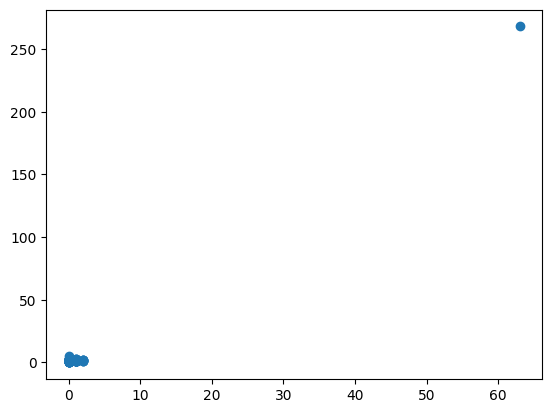

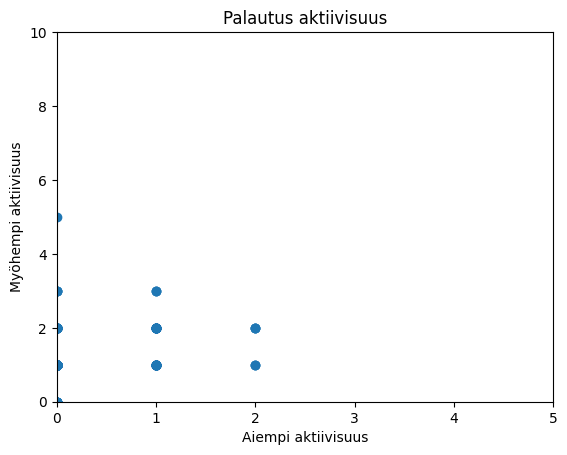

268.0 0.0
63.0 0.0


In [7]:
import matplotlib.pyplot as plt
activity = logs1[logs1["Kuvaus"].isin(["Tenttivastaus palautettu", "Palautus on lähetetty"])]
neljannes = ((activity["Aika"].max()-activity["Aika"].min()))/4
print(neljannes.days)
early = activity[activity["Aika"]-activity["Aika"].min() <= neljannes]
later = activity[activity["Aika"]-activity["Aika"].min() > neljannes]
earlyavgs = np.empty(shape=0)
lateravgs = np.empty(shape=0)
for i in ids:
    sr = "The user with id '"+i
    earlyactivity = len(early[early["Alkuperä"].str.startswith(sr) == True].index) + len(early[early["Unnamed: 6"].str.startswith(sr) == True].index)
    lateractivity = len(later[later["Alkuperä"].str.startswith(sr) == True].index) + len(later[later["Unnamed: 6"].str.startswith(sr) == True].index)
    earlyavgs = np.append(earlyavgs, earlyactivity)
    lateravgs = np.append(lateravgs, lateractivity)
plt.scatter(earlyavgs, lateravgs)
plt.show()
plt.title("Palautus aktiivisuus")
plt.xlim(0, 5)
plt.xlabel("Aiempi aktiivisuus")
plt.ylim(0, 10)
plt.ylabel("Myöhempi aktiivisuus")
plt.scatter(earlyavgs, lateravgs)
plt.show()
print(lateravgs.max(), lateravgs.min())
print(earlyavgs.max(), earlyavgs.min())

21


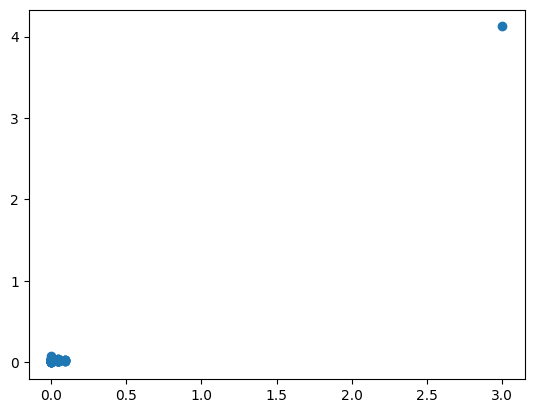

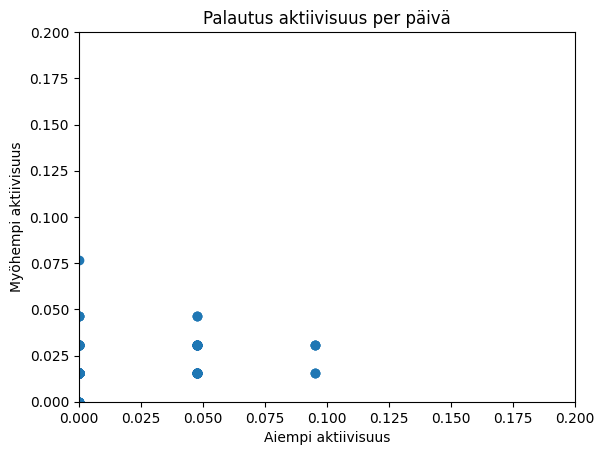

4.123076923076923 0.0
3.0 0.0


In [8]:
activity = logs1[logs1["Kuvaus"].isin(["Tenttivastaus palautettu", "Palautus on lähetetty"])]
neljannes = ((activity["Aika"].max()-activity["Aika"].min()))/4
print(neljannes.days)
early = activity[activity["Aika"]-activity["Aika"].min() <= neljannes]
later = activity[activity["Aika"]-activity["Aika"].min() > neljannes]
earlyavgs = np.empty(shape=0)
lateravgs = np.empty(shape=0)
for i in ids:
    sr = "The user with id '"+i
    earlyactivity = len(early[early["Alkuperä"].str.startswith(sr) == True].index) + len(early[early["Unnamed: 6"].str.startswith(sr) == True].index)
    lateractivity = len(later[later["Alkuperä"].str.startswith(sr) == True].index) + len(later[later["Unnamed: 6"].str.startswith(sr) == True].index)
    earlyavgs = np.append(earlyavgs, earlyactivity/neljannes.days)
    lateravgs = np.append(lateravgs, lateractivity/(((activity["Aika"].max()-activity["Aika"].min())).days-neljannes.days))
plt.scatter(earlyavgs, lateravgs)
plt.show()
plt.title("Palautus aktiivisuus per päivä")
plt.xlim(0, 0.2)
plt.xlabel("Aiempi aktiivisuus")
plt.ylim(0, 0.2)
plt.ylabel("Myöhempi aktiivisuus")
plt.scatter(earlyavgs, lateravgs)
plt.show()
print(lateravgs.max(), lateravgs.min())
print(earlyavgs.max(), earlyavgs.min())